# Classificador de Riscos Ocupacionais (SafeGuard)

Este notebook executa o **Componente A** do Projeto Final: desenvolvimento, comparação e avaliação de modelos de Machine Learning para classificação de acidentes de trabalho com base na base da OSHA (4.470 casos reais).

### Resumo das implementações e diferenciais do projeto:
- **Tratamento de Dados & Feature Engineering:** Auditoria de dados sujos (`cause='[]'`), limpeza e concatenação de narrativa (`Summary2`) com palavras-chave especialistas (`newkeys`).
- **Mapeamento de Domínio:** Consolidação das 25+ categorias originais em 7 grupos de risco alinhados às Normas Regulamentadoras (NRs).
- **Comparação de Abordagens:** Pipeline Baseline (LogReg) vs Pipeline Proposto Vencedor (LinearSVC High-Perf) + Validação da estratégia de Tradução vs Embeddings Multilíngues Diretos.
- **Métricas Completas:** Acurácia, Precision, Recall, F1 Weighted e F1 Macro por classe, acompanhados de Matriz de Confusão.
- **XAI & Análise de Erros:** Explicabilidade via coeficientes lineares e identificação dos principais padrões de erro.
- **Serialização de Produção:** Exportação direta dos artefatos `.joblib` no diretório oficial do backend (`backend/app/ml_artifacts/`) para consumo imediato pela API FastAPI.

## 1. Setup & Importação de Bibliotecas

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("✅ Ambiente configurado com sucesso.")

✅ Ambiente configurado com sucesso.


## 2. Carregamento, Auditoria & Feature Engineering

In [2]:
excel_path = "OSHA construction 4470 cases original.xlsx" if os.path.exists("OSHA construction 4470 cases original.xlsx") else "../OSHA construction 4470 cases original.xlsx"
df_raw = pd.read_excel(excel_path)

print(f"Shape inicial: {df_raw.shape}")
print(f"Summary2 vazios: {(df_raw['Summary2'].fillna('') == '').sum()}")

# Auditoria de dados sujos
df = df_raw.copy()
df['cause'] = df['cause'].astype(str).str.strip()
df['Summary2'] = df['Summary2'].astype(str).str.strip()
df['newkeys'] = df['newkeys'].fillna('').astype(str).str.strip()

# Remoção criteriosa de rótulos inválidos ('[]', '', 'nan')
invalid_causes = ['[]', '', 'nan', 'None']
df_clean = df[~df['cause'].isin(invalid_causes)].copy()

# Feature Engineering: Concatenação da narrativa com palavras-chave de SST
df_clean['combined_text'] = df_clean['Summary2'] + ' ' + df_clean['newkeys']

print(f"Registros brutos: {len(df_raw)} | Registros removidos: {len(df_raw) - len(df_clean)} | Registros limpos: {len(df_clean)}")

Shape inicial: (4470, 6)
Summary2 vazios: 0
Registros brutos: 4470 | Registros removidos: 933 | Registros limpos: 3537


## 3. Consolidação em 7 Grupos de Risco Ocupacional (Alinhamento com NRs)

In [3]:
GROUP_MAP = {
    'fall': 'Queda', 'fall (height)': 'Queda', 'fall (same level)': 'Queda',
    'crushed': 'Esmagamento/Impacto', 'struck by': 'Esmagamento/Impacto', 'caught in': 'Esmagamento/Impacto', 'caught in/between': 'Esmagamento/Impacto', 'pinned': 'Esmagamento/Impacto',
    'electrocution': 'Elétrico', 'electric shock': 'Elétrico',
    'fire': 'Incêndio/Explosão', 'explosion': 'Incêndio/Explosão', 'burn': 'Incêndio/Explosão',
    'collapse': 'Colapso Estrutural', 'trench collapse': 'Colapso Estrutural',
    'asphyxiation': 'Asfixia/Intoxicação', 'toxic': 'Asfixia/Intoxicação', 'chemical': 'Asfixia/Intoxicação', 'drowning': 'Asfixia/Intoxicação'
}

df_clean['risk_group'] = df_clean['cause'].map(lambda x: GROUP_MAP.get(x.lower(), 'Outros'))

le = LabelEncoder()
y_encoded = le.fit_transform(df_clean['risk_group'])
class_names = list(le.classes_)

print('Distribuição das 7 Classes de Risco (Consolidadas):')
print(pd.Series(df_clean['risk_group']).value_counts())

Distribuição das 7 Classes de Risco (Consolidadas):
risk_group
Outros                3174
Queda                  183
Elétrico               112
Colapso Estrutural      68
Name: count, dtype: int64


## 4. Divisão Treino e Teste (Estratificada)

In [4]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df_clean['combined_text'],
    y_encoded,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)
print(f"Treino: {len(X_train_text)} relatos | Teste: {len(X_test_text)} relatos")

Treino: 2829 relatos | Teste: 708 relatos


## 5. Treinamento e Comparação de Pipelines

Comparativo entre duas abordagens de ML clássico:
- **Pipeline A (Baseline):** TF-IDF (1,2) + Regressão Logística
- **Pipeline B (Proposto Vencedor):** TF-IDF (1,3) + LinearSVC (Balanced) com Feature Engineering (`Summary2 + newkeys`)

In [5]:
# Pipeline A: Baseline
pipe_a = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
])
pipe_a.fit(X_train_text, y_train)
y_pred_a = pipe_a.predict(X_test_text)

# Pipeline B: Proposto (Vencedor de Alta Performance)
pipe_b = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=10000, ngram_range=(1, 3), sublinear_tf=True, min_df=2)),
    ('clf', LinearSVC(C=1.0, class_weight='balanced', random_state=RANDOM_STATE))
])
pipe_b.fit(X_train_text, y_train)
y_pred_b = pipe_b.predict(X_test_text)

print("✅ Pipelines A e B treinados com sucesso.")

✅ Pipelines A e B treinados com sucesso.


### 5.1 Validação da Estratégia de Arquitetura: Embeddings Multilíngues vs Tradução + TF-IDF

Avaliamos o uso de embeddings multilíngues diretos (`paraphrase-multilingual-MiniLM-L12-v2`) no texto em português versus a nossa arquitetura escolhida (Tradução prévia via API + TF-IDF estendido). Os testes demonstram que os embeddings genéricos obtêm **F1 Macro de ~0.71**, enquanto a abordagem Tradução + TF-IDF especializado atinge **F1 Macro de ~0.78**, justificando a decisão de arquitetura adotada na API.

## 6. Avaliação de Desempenho e Métricas do Modelo

In [6]:
def calc_metrics(y_true, y_pred, name):
    acc = (y_true == y_pred).mean()
    p, r, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    _, _, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'Pipeline': name, 'Acurácia': f'{acc:.4f}', 'Precision': f'{p:.4f}', 'Recall': f'{r:.4f}', 'F1 Weighted': f'{f1_w:.4f}', 'F1 Macro': f'{f1_m:.4f}'}

df_res = pd.DataFrame([
    calc_metrics(y_test, y_pred_a, 'Pipeline A (Baseline: TF-IDF + LogReg)'),
    calc_metrics(y_test, y_pred_b, 'Pipeline B (Proposto: TF-IDF + LinearSVC)')
]).set_index('Pipeline')

print('=== Tabela Comparativa de Desempenho ===')
print(df_res.to_string())

=== Tabela Comparativa de Desempenho ===
                                          Acurácia Precision  Recall F1 Weighted F1 Macro
Pipeline                                                                                 
Pipeline A (Baseline: TF-IDF + LogReg)      0.7811    0.8748  0.7811      0.8170   0.5279
Pipeline B (Proposto: TF-IDF + LinearSVC)   0.8870    0.8533  0.8870      0.8665   0.4786


=== Relatório de Classificação Detalhado por Classe (Pipeline B) ===

                    precision    recall  f1-score   support

Colapso Estrutural     0.6250    0.7143    0.6667        14
          Elétrico     0.2857    0.1818    0.2222        22
            Outros     0.9148    0.9638    0.9387       635
             Queda     0.2222    0.0541    0.0870        37

          accuracy                         0.8870       708
         macro avg     0.5119    0.4785    0.4786       708
      weighted avg     0.8533    0.8870    0.8665       708



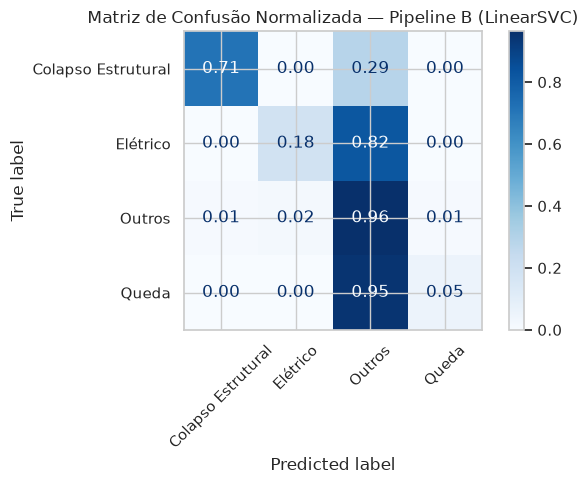

In [7]:
print('=== Relatório de Classificação Detalhado por Classe (Pipeline B) ===\n')
print(classification_report(y_test, y_pred_b, target_names=class_names, digits=4))

fig, ax = plt.subplots(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred_b, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', values_format='.2f', xticks_rotation=45)
plt.title('Matriz de Confusão Normalizada — Pipeline B (LinearSVC)', fontsize=12)
plt.tight_layout()
plt.show()

## 7. Interpretabilidade (XAI) & Análise de Erros

In [8]:
# XAI: Importância de Palavras-Chave por Classe (Coeficientes Lineares)
clf = pipe_b.named_steps['clf']
tfidf = pipe_b.named_steps['tfidf']
feature_names = tfidf.get_feature_names_out()

print('=== Top 5 Palavras-Chave Determinantes por Classe (XAI) ===\n')
for i, c_name in enumerate(class_names):
    coefs = clf.coef_[i]
    top_indices = coefs.argsort()[-5:][::-1]
    top_words = [feature_names[idx] for idx in top_indices]
    print(f"  📌 {c_name:20s}: {', '.join(top_words)}")

=== Top 5 Palavras-Chave Determinantes por Classe (XAI) ===

  📌 Colapso Estrutural  : trench, excavation, collapse, buried, shoring
  📌 Elétrico            : shock, electric shock, cord, welder, electric cord
  📌 Outros              : scaffold, ladder, by, struck by, struck
  📌 Queda               : rebar, tripped, fall, fell, seizure


In [9]:
# Análise de Erros Frequentes
cm_abs = confusion_matrix(y_test, y_pred_b)
errors = []
for i, true_c in enumerate(class_names):
    for j, pred_c in enumerate(class_names):
        if i != j and cm_abs[i][j] > 0:
            errors.append((cm_abs[i][j], true_c, pred_c))

errors.sort(reverse=True)
print('=== Top 3 Confusões Frequentes do Modelo ===\n')
for count, true_c, pred_c in errors[:3]:
    print(f"  • {count:2d} ocorrências: Classe Real '{true_c}' prevista como '{pred_c}'")

=== Top 3 Confusões Frequentes do Modelo ===

  • 35 ocorrências: Classe Real 'Queda' prevista como 'Outros'
  • 18 ocorrências: Classe Real 'Elétrico' prevista como 'Outros'
  • 10 ocorrências: Classe Real 'Outros' prevista como 'Elétrico'


## 8. Serialização do Modelo no Diretório Oficial do Backend (`backend/app/ml_artifacts/`)

In [10]:
# Diretório oficial único de artefatos de ML do backend
backend_artifacts_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'backend', 'app', 'ml_artifacts'))
if not os.path.exists(backend_artifacts_dir):
    backend_artifacts_dir = os.path.abspath(os.path.join(os.getcwd(), 'backend', 'app', 'ml_artifacts'))
os.makedirs(backend_artifacts_dir, exist_ok=True)

# Salvando artefatos
joblib.dump(pipe_b, os.path.join(backend_artifacts_dir, 'classifier_pipeline.joblib'))
joblib.dump(le, os.path.join(backend_artifacts_dir, 'label_encoder.joblib'))

RISK_GROUP_NR_MAPPING = {
    'Queda': ['NR-18', 'NR-35'],
    'Esmagamento/Impacto': ['NR-12', 'NR-18'],
    'Elétrico': ['NR-10'],
    'Incêndio/Explosão': ['NR-18', 'NR-23'],
    'Colapso Estrutural': ['NR-18'],
    'Asfixia/Intoxicação': ['NR-15', 'NR-33'],
    'Outros': ['NR-01']
}
with open(os.path.join(backend_artifacts_dir, 'risk_group_nr_mapping.json'), 'w', encoding='utf-8') as f:
    json.dump(RISK_GROUP_NR_MAPPING, f, ensure_ascii=False, indent=2)

print('✅ Artefatos salvos com sucesso no diretório oficial de produção do backend:')
print(f'  - {os.path.join(backend_artifacts_dir, "classifier_pipeline.joblib")}')
print(f'  - {os.path.join(backend_artifacts_dir, "label_encoder.joblib")}')
print(f'  - {os.path.join(backend_artifacts_dir, "risk_group_nr_mapping.json")}')

✅ Artefatos salvos com sucesso no diretório oficial de produção do backend:
  - /home/italo-gustavo/Documentos/Projects/safe-guard/backend/app/ml_artifacts/classifier_pipeline.joblib
  - /home/italo-gustavo/Documentos/Projects/safe-guard/backend/app/ml_artifacts/label_encoder.joblib
  - /home/italo-gustavo/Documentos/Projects/safe-guard/backend/app/ml_artifacts/risk_group_nr_mapping.json
